# 02 · Bandit warm-up: checking the gradient estimators

Before using the estimators on poems, we test the **same code** (`poet.policy`, `poet.estimators`, `poet.train`)
on a problem where the true policy gradient is known in closed form.


## Setup: a *repeated* 2-armed bandit

A one-pull bandit is too easy a test. With horizon 1, REINFORCE and GPOMDP are the same formula, so it could
not catch a bug in GPOMDP's handling of time. So each episode pulls an arm **up to $H=10$ times**:

- arm $a$ pays $r = \mu_a + \varepsilon$, with $\varepsilon \sim \mathcal N(0, 0.5^2)$, $\mu = (1.0,\ 1.5)$: arm 1 is better;
- after every pull the episode stops with probability $q = 0.2$, independently of the action.
  Episodes therefore have **variable length** $1..H$, as poems do, and the code path that pads episodes to
  horizon $T=H$ gets exercised;
- the policy is a stateless softmax $\pi_\theta(a) \propto \exp(\theta_a/\tau)$, $\tau=1$, initialised like the poem
  policy, $\theta_0 = \tau \log p_0$ with a "prior" $p_0 = (0.8,\ 0.2)$ that prefers the **worse** arm.

**Exact gradient.** The stopping time does not depend on the actions, so
$J(\theta) = \mathbb E[\text{length}]\ \sum_a \pi_\theta(a)\mu_a$ with
$\mathbb E[\text{length}] = \sum_{t=0}^{H-1}(1-q)^t$. Using $\partial \pi(a)/\partial\theta_b = \pi(a)(\mathbb 1\{a=b\}-\pi(b))/\tau$,

$$\frac{\partial J}{\partial \theta_a} = \mathbb E[\text{length}]\ \frac{\pi(a)\,\big(\mu_a - \textstyle\sum_b \pi(b)\mu_b\big)}{\tau}.$$

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('..') / 'src'))

import numpy as np
import matplotlib.pyplot as plt
from poet.bandit import RepeatedBandit
from poet.policy import TabularSoftmax, rollout, add_score
from poet import estimators as E, train, stats

SEED = 0
TAU = 1.0
PRIOR = np.array([0.8, 0.2])
env = RepeatedBandit(mu=[1.0, 1.5], sigma=0.5, H=10, q=0.2)
METHODS_ALL = E.METHODS + ['ac']
plt.rcParams['figure.dpi'] = 110

def make_policy(prior=PRIOR):
    # theta_0 = tau * log p_0, so that pi_theta0 = p_0 (same initialisation as the poem policy)
    return TabularSoftmax(lambda s: TAU * np.log(prior), TAU)

pol = make_policy()
print('E[length] =', round(env.expected_length(), 3))
print('pi_theta0 =', pol.probs(0), '  J(theta0) =', round(env.J(pol.probs(0)), 3))
print('exact gradient at theta0 =', env.exact_gradient(pol.probs(0), TAU))

E[length] = 4.463
pi_theta0 = [0.8 0.2]   J(theta0) = 4.909
exact gradient at theta0 = [-0.35705033  0.35705033]


## Check 1: the two forms of GPOMDP give the same number

`poet.estimators.gpomdp` computes the **first form** of GPOMDP (score at step $h$ times the reward-to-go).
Here we compute the **second form** directly from its definition, with $T$ padded and $r_t=0$ after the end,
$\frac1n\sum_i\sum_{t=0}^{T-1}(r^i_t - b_t)\sum_{h\le t}\nabla\log\pi(A^i_h|S^i_h)$,
and check that both agree to machine precision on a random batch, with and without $b_t$.

In [2]:
def gpomdp_second_form(trajs, tau, T, baseline):
    # straight from the formula: for every t, the reward (minus b_t) times the cumulative score up to t
    n = len(trajs)
    r = E.padded_rewards(trajs, T)
    b = E.leave_one_out_mean(r) if baseline else np.zeros_like(r)
    grad = {}
    for i, tr in enumerate(trajs):
        for t in range(T):
            for h in range(min(t + 1, len(tr))):       # after the end there are no more score terms
                add_score(grad, tr.states[h], tr.probs[h], tr.actions[h], (r[i, t] - b[i, t]) / n, tau)
    return grad

rng = np.random.default_rng(SEED)
batch = [rollout(env, pol, rng) for _ in range(10)]
print('episode lengths in the batch:', [len(tr) for tr in batch])
for baseline in (False, True):
    g1 = E.gpomdp(batch, TAU, env.horizon, baseline)[0]
    g2 = gpomdp_second_form(batch, TAU, env.horizon, baseline)[0]
    print(f'baseline={baseline!s:5}  first form {g1}   second form {g2}   max |diff| = {np.abs(g1 - g2).max():.1e}')
    assert np.allclose(g1, g2)

episode lengths in the batch: [1, 3, 3, 4, 7, 2, 1, 10, 10, 10]
baseline=False  first form [-0.20418793  0.20418793]   second form [-0.20418793  0.20418793]   max |diff| = 1.9e-15
baseline=True   first form [-0.48836203  0.48836203]   second form [-0.48836203  0.48836203]   max |diff| = 9.4e-16


## Check 2: all four estimators are unbiased

We draw $M = 4000$ independent batches of $n = 10$ episodes at a fixed $\theta$ and average the estimates.
An unbiased estimator must agree with the exact gradient up to Monte Carlo error. We report the 95% interval of
the mean and $z = (\text{mean}-\text{exact})/\text{s.e.}$ The two components are always opposite
($\sum_a \partial\log\pi(a)/\partial\theta = 0$ for a softmax), so we show the arm-1 component.

We check at two parameters: the initial $\theta_0$ (prior 0.8/0.2) and the uniform policy.

In [3]:
M, N_BATCH = 4000, 10

def sample_estimates(policy, method, M, n, rng):
    return np.array([E.estimate(method, [rollout(env, policy, rng) for _ in range(n)], TAU, env.horizon)[0]
                     for _ in range(M)])

estimates = {}
for name, prior in [('theta0 (0.8/0.2)', PRIOR), ('uniform', np.array([0.5, 0.5]))]:
    p = make_policy(prior)
    exact = env.exact_gradient(p.probs(0), TAU)[1]
    print(f'\n=== {name}: exact dJ/dtheta_1 = {exact:.4f}')
    print(f'{"method":24s} {"mean":>8s} {"95% CI":>20s} {"z":>6s} {"variance":>9s}')
    for m in E.METHODS:
        G = sample_estimates(p, m, M, N_BATCH, np.random.default_rng(SEED))[:, 1]
        mean, hw = stats.mean_ci(G)
        z = (mean - exact) / (G.std(ddof=1) / np.sqrt(M))
        estimates[(name, m)] = G
        print(f'{E.LABELS[m]:24s} {mean:8.4f} [{mean - hw:8.4f}, {mean + hw:8.4f}] {z:6.2f} {G.var(ddof=1):9.4f}')


=== theta0 (0.8/0.2): exact dJ/dtheta_1 = 0.3571
method                       mean               95% CI      z  variance


REINFORCE                  0.3310 [  0.2614,   0.4005]  -0.73    5.0381


REINFORCE + baseline       0.3502 [  0.3120,   0.3884]  -0.35    1.5205


GPOMDP                     0.3521 [  0.3064,   0.3977]  -0.21    2.1712


GPOMDP + baseline b_t      0.3593 [  0.3294,   0.3891]   0.15    0.9276

=== uniform: exact dJ/dtheta_1 = 0.5579
method                       mean               95% CI      z  variance


REINFORCE                  0.4937 [  0.3958,   0.5917]  -1.28    9.9907


REINFORCE + baseline       0.5351 [  0.4826,   0.5877]  -0.85    2.8760


GPOMDP                     0.5504 [  0.4881,   0.6127]  -0.24    4.0371


GPOMDP + baseline b_t      0.5521 [  0.5117,   0.5926]  -0.28    1.7043


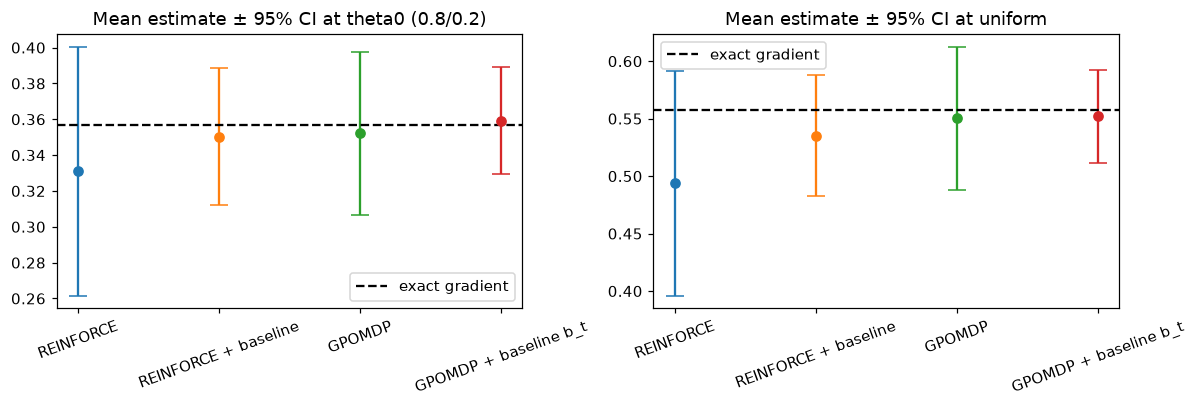

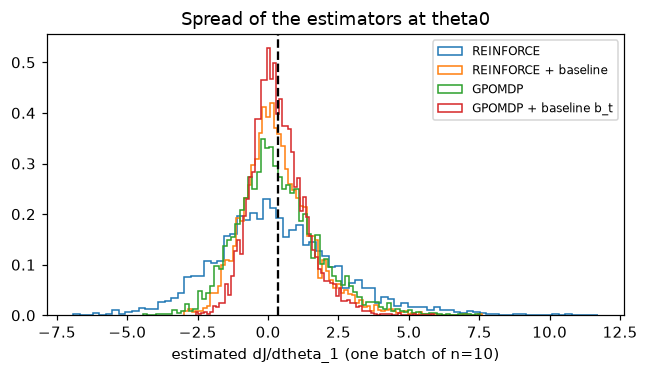

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, name, prior in zip(axes, ['theta0 (0.8/0.2)', 'uniform'], [PRIOR, np.array([0.5, 0.5])]):
    exact = env.exact_gradient(make_policy(prior).probs(0), TAU)[1]
    for k, m in enumerate(E.METHODS):
        mean, hw = stats.mean_ci(estimates[(name, m)])
        ax.errorbar(k, mean, yerr=hw, fmt='o', capsize=6, color=f'C{k}')
    ax.axhline(exact, color='k', ls='--', label='exact gradient')
    ax.set_xticks(range(4)); ax.set_xticklabels([E.LABELS[m] for m in E.METHODS], rotation=20)
    ax.set_title(f'Mean estimate ± 95% CI at {name}'); ax.legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 3.5))
for k, m in enumerate(E.METHODS):
    ax.hist(estimates[('theta0 (0.8/0.2)', m)], bins=80, histtype='step', density=True, label=E.LABELS[m], color=f'C{k}')
ax.axvline(env.exact_gradient(make_policy().probs(0), TAU)[1], color='k', ls='--')
ax.set_xlabel('estimated dJ/dtheta_1 (one batch of n=10)'); ax.set_title('Spread of the estimators at theta0')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Why a leave-one-out baseline.** If the average baseline is computed on the *same* batch, it
depends on $\tau_i$ itself and the estimator becomes slightly biased. For REINFORCE the bias is exact and easy to see:
with $b = \frac1n\sum_j R(\tau_j)$ we get $R_i - b = \frac{n-1}{n}\,(R_i - b^{(-i)})$, where $b^{(-i)}$ is the
leave-one-out mean. So the same-batch version is the unbiased estimator **shrunk by the factor $(n-1)/n$**. With $n=2$
the gradient is halved:

In [5]:
def reinforce_same_batch_baseline(trajs, tau):
    n = len(trajs)
    R = np.array([tr.ret for tr in trajs])
    grad = {}
    for tr, coef in zip(trajs, R - R.mean()):
        for s, a, p in zip(tr.states, tr.actions, tr.probs):
            add_score(grad, s, p, a, coef / n, tau)
    return grad

p = make_policy()
exact = env.exact_gradient(p.probs(0), TAU)[1]
M_LOO = 40000          # more batches than above: the n=2 estimator is very noisy
for n in (2, 10):
    rng = np.random.default_rng(SEED)
    same, loo = [], []
    for _ in range(M_LOO):
        trajs = [rollout(env, p, rng) for _ in range(n)]
        same.append(reinforce_same_batch_baseline(trajs, TAU)[0][1])
        loo.append(E.reinforce(trajs, TAU, baseline=True)[0][1])
    (ms, hs), (ml, hl) = stats.mean_ci(same), stats.mean_ci(loo)
    print(f'n={n:2d}: exact {exact:.4f} | same-batch mean {ms:.4f} ± {hs:.4f} (expected (n-1)/n*exact = {(n-1)/n*exact:.4f})'
          f' | leave-one-out {ml:.4f} ± {hl:.4f}')

n= 2: exact 0.3571 | same-batch mean 0.1819 ± 0.0167 (expected (n-1)/n*exact = 0.1785) | leave-one-out 0.3637 ± 0.0333


n=10: exact 0.3571 | same-batch mean 0.3143 ± 0.0109 (expected (n-1)/n*exact = 0.3213) | leave-one-out 0.3493 ± 0.0121


## Check 3: training converges to the better arm

Every method starts from $\theta_0$ (prior 0.8 on the **worse** arm) and trains for 2000 episodes; 20 seeds each.
Batch methods use $n=10$ episodes per update. The actor-critic (adapted to $\gamma=1$, see
notebook 04) updates after every step. Its critic is a single number $V(0)$, because the bandit has only one state.
Evaluation is **exact**: we read $\pi_\theta(\text{arm }1)$ and $J(\theta)$ directly, with no sampling.

First a small step-size grid. For each method we report the fraction of seeds that end with
$\pi_\theta(\text{arm 1}) > 0.9$.

In [6]:
N_EPISODES, N_SEEDS, EVAL_EVERY = 2000, 20, 50
ALPHAS = [0.01, 0.03, 0.1, 0.3]
BETA_FACTOR = 10           # actor-critic: critic step beta = 10 * alpha (and capped at 1)

def evaluate(policy):
    pi = policy.probs(0)
    return {'pi_best': float(pi[1]), 'J': env.J(pi)}

def run(method, alpha, seed):
    policy = make_policy()
    rng = np.random.default_rng(seed)
    if method == 'ac':
        h, _ = train.train_actor_critic(env, policy, alpha, min(BETA_FACTOR * alpha, 1.0), N_EPISODES, rng, evaluate, EVAL_EVERY)
    else:
        h = train.train_batch_pg(env, policy, method, alpha, 10, N_EPISODES, rng, evaluate, EVAL_EVERY)
    return h

runs = {(m, a): [run(m, a, seed) for seed in range(N_SEEDS)] for m in METHODS_ALL for a in ALPHAS}

print('fraction of seeds with final pi(arm 1) > 0.9   [fraction stuck on the WORSE arm, final pi(arm 1) < 0.1]')
print(f'{"method":24s}' + ''.join(f'{"alpha=" + str(a):>18s}' for a in ALPHAS))
for m in METHODS_ALL:
    row = ''
    for a in ALPHAS:
        final = np.array([h['eval_pi_best'][-1] for h in runs[(m, a)]])
        row += f'{(final > 0.9).mean():>10.2f} [{(final < 0.1).mean():.2f}]'
    print(f'{E.LABELS[m]:24s}' + row)

fraction of seeds with final pi(arm 1) > 0.9   [fraction stuck on the WORSE arm, final pi(arm 1) < 0.1]
method                          alpha=0.01        alpha=0.03         alpha=0.1         alpha=0.3
REINFORCE                     0.00 [0.00]      0.90 [0.00]      0.85 [0.10]      0.50 [0.50]
REINFORCE + baseline          0.00 [0.00]      0.90 [0.00]      1.00 [0.00]      0.95 [0.05]
GPOMDP                        0.00 [0.00]      0.80 [0.00]      0.95 [0.00]      0.85 [0.15]
GPOMDP + baseline b_t         0.00 [0.00]      0.95 [0.00]      1.00 [0.00]      1.00 [0.00]
Actor-critic                  1.00 [0.00]      1.00 [0.00]      1.00 [0.00]      0.90 [0.10]


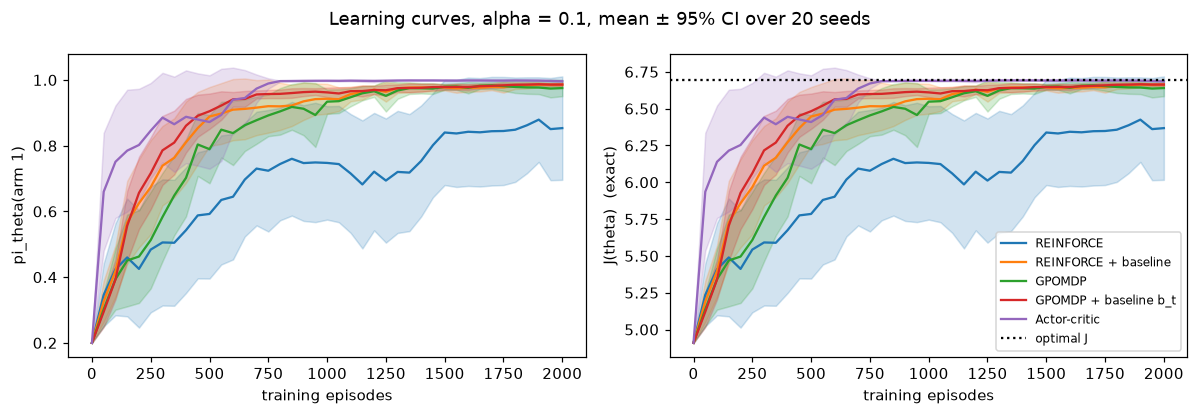

In [7]:
ALPHA_SHOW = 0.1
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for k, m in enumerate(METHODS_ALL):
    hs = runs[(m, ALPHA_SHOW)]
    x = hs[0]['eval_episodes']
    for ax, key in zip(axes, ['pi_best', 'J']):
        mean, hw = stats.mean_ci([h['eval_' + key] for h in hs])
        ax.plot(x, mean, color=f'C{k}', label=E.LABELS[m])
        ax.fill_between(x, mean - hw, mean + hw, color=f'C{k}', alpha=0.2)
axes[0].set_ylabel('pi_theta(arm 1)'); axes[1].set_ylabel('J(theta)  (exact)')
axes[1].axhline(env.expected_length() * env.mu.max(), color='k', ls=':', label='optimal J')
for ax in axes:
    ax.set_xlabel('training episodes')
axes[1].legend(fontsize=8)
fig.suptitle(f'Learning curves, alpha = {ALPHA_SHOW}, mean ± 95% CI over {N_SEEDS} seeds')
plt.tight_layout(); plt.show()

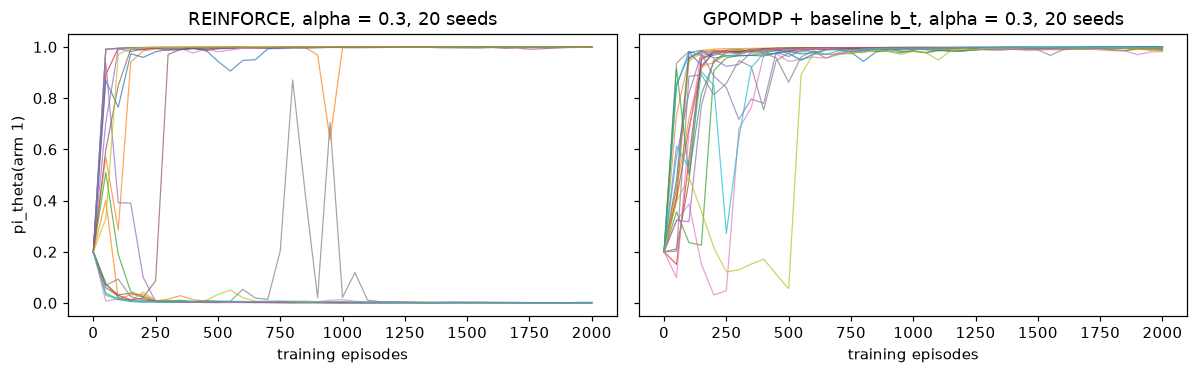

In [8]:
# Individual seeds of plain REINFORCE at the largest step size: where does the failure come from?
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, m in zip(axes, ['reinforce', 'gpomdp_b']):
    for h in runs[(m, 0.3)]:
        ax.plot(h['eval_episodes'], h['eval_pi_best'], lw=0.8, alpha=0.7)
    ax.set_title(f'{E.LABELS[m]}, alpha = 0.3, {N_SEEDS} seeds'); ax.set_xlabel('training episodes')
axes[0].set_ylabel('pi_theta(arm 1)')
plt.tight_layout(); plt.show()

## Discussion

- **The estimator code is correct.** All four estimators agree with the closed-form gradient at two different
  parameters ($|z|$ of order 1 or less), and the two forms of GPOMDP coincide to machine precision. Padding to the
  common horizon $T$ is handled consistently.
- **Variance ranking** (same at both parameters): REINFORCE (5.0) > GPOMDP (2.2) > REINFORCE + $b$ (1.5) >
  GPOMDP + $b_t$ (0.9), the values being at $\theta_0$. Rewards here are all positive (around 1–1.5 per pull), so
  without a baseline every sampled action gets *reinforced*, and the useful signal is only the difference between
  arms. Centering removes most of this noise. GPOMDP helps because a reward cannot be caused by later actions,
  so dropping those terms removes noise without adding bias. The two techniques combine.
- **Leave-one-out baseline.** The same-batch average baseline shrinks REINFORCE's expected gradient by $(n-1)/n$:
  it is half the true gradient at $n=2$. The leave-one-out version is unbiased for every $n$. We use leave-one-out
  everywhere (for $b$ and for $b_t$).
- **Training.** With a reasonable step size ($\alpha = 0.03$–$0.1$) every method moves from the prior on the worse arm
  to the better arm. At $\alpha = 0.01$ the batch methods are simply too slow for 2000 episodes (200 updates).
  At $\alpha=0.3$, **half of the plain REINFORCE runs jump onto the wrong arm and stay there**, against 15% for
  GPOMDP, 5% for REINFORCE + $b$ and none for GPOMDP + $b_t$. Once $\pi_\theta(\text{arm }1)\approx 0$ the softmax
  gradient $\pi(a)(\mu_a-\bar\mu)/\tau$ vanishes, so one unlucky high-variance step becomes permanent. The failure
  rate follows the variance ranking above. This is a first sign of what variance reduction buys: a **larger usable
  step size**, and therefore fewer episodes to reach a target.
- **Actor-critic.** It converges at every step size except the largest, and fastest at small $\alpha$. It updates
  after every *step*, while a batch method makes one update per $n=10$ episodes, so on the same $\alpha$ grid its
  effective step is much larger. Notebook 04 tunes every method on the same grid for this reason. Its critic is a single
  number for the whole episode (the bandit has one state), which foreshadows the state-aliasing issue of notebook 03.